# Fase III — Análisis de sensibilidad de la Formulación II
## Trabajo 01 · Estructura N.º 8 · Confluencia o bifurcación de canales

**Curso:** Flujo en superficie libre — UNSCH, Unidad de Posgrado

**Objetivo.** Cuantificar cuánto cambia el reparto de caudales de la bifurcación cuando cambian los parámetros de entrada, con **13 parámetros** (el enunciado exige al menos 5) y **elasticidades**

$$E_{y,p}=\frac{\partial y}{\partial p}\,\frac{p}{y}\qquad\text{(variación porcentual de la salida por cada 1 \% de variación del parámetro).}$$

**Modelo.** Formulación II de las Partes 1 y 2 (nivel común $H_J$, energía por ramal con pérdida local $K_i$ y Manning), con el **código sin cambios**. Referencia de la forma del sistema en una unión: Chaudhry (2008), Ecs. 6-58 a 6-63. Los datos son los **hipotéticos** de la Parte 1 (`datos_entrada.json`).

**Salidas analizadas.** Modo A (análisis): fracción derivada $\varphi=Q_2/Q_0$, caudales $Q_1$ y $Q_2$, y tirante en la unión $y_J=H_J-z_J$ (se usa $y_J$ y no $H_J$ porque la cota del datum, 100 m, haría que la elasticidad de $H_J$ no significara nada). Modo B (diseño): ancho requerido $b_2$.

| Etapa | Qué se hace | Pruebas |
|---|---|---|
| 1 | Elasticidades locales por el **teorema de la función implícita**, $\partial\mathbf X/\partial p=-\mathbf J^{-1}\partial\mathbf F/\partial p$ | V1 a V4 |
| 2 | Barrido no lineal de ±20 % (gráfico araña) y diagrama de tornado a ±10 % | – |
| 3 | Elasticidades del modo de diseño ($b_2$) | – |
| 4 | Propagación de incertidumbre: aporte de cada parámetro a la varianza de $\varphi$, con comprobación por Monte Carlo | V5 |

## 1. Librerías y versiones

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

print('Python     :', sys.version.split()[0])
print('NumPy      :', np.__version__)
print('pandas     :', pd.__version__)
print('matplotlib :', matplotlib.__version__)
import copy

Python     : 3.13.16
NumPy      : 2.5.3
pandas     : 3.0.5
matplotlib : 3.11.2


## 2. Código de la Formulación II (sin cambios)

Se reutilizan exactamente las funciones de la Parte 1: `pendiente_friccion`, `ramal`, `crear_sistema`, `newton_amortiguado` y `valor_inicial`.

In [2]:
def pendiente_friccion(n, Q, b, y):
    """Sf de Manning en canal rectangular y sus derivadas parciales (Q, y, b)."""
    A = b*y
    P = b + 2*y
    Sf = n**2 * Q**2 * P**(4/3) / A**(10/3)
    dSf_dQ = 2*Sf/Q
    dSf_dy = Sf*(8/(3*P) - 10/(3*y))
    dSf_db = Sf*(4/(3*P) - 10/(3*b))
    return Sf, dSf_dQ, dSf_dy, dSf_db


def ramal(Q, b, HJ, p, g):
    """Ecuacion de energia G de un ramal (union -> control) y sus derivadas.
    Devuelve (G, dG/dQ, dG/dHJ, dG/db) o None si el estado es inadmisible."""
    n, L, zJ, S, yd, K = p["n"], p["L"], p["zJ"], p["S"], p["yd"], p["K"]
    zd = zJ - S*L                     # cota de fondo en la seccion de control
    yJ = HJ - zJ                      # tirante en la union
    if Q <= 0 or b <= 0 or yJ <= 0:
        return None
    AJ, Ad = b*yJ, b*yd
    SfJ, dSfJ_dQ, dSfJ_dy, dSfJ_db = pendiente_friccion(n, Q, b, yJ)
    Sfd, dSfd_dQ, _,        dSfd_db = pendiente_friccion(n, Q, b, yd)

    G = (HJ + (1-K)*Q**2/(2*g*AJ**2)
         - (zd + yd) - Q**2/(2*g*Ad**2)
         - 0.5*L*(SfJ + Sfd))

    dG_dQ  = (1-K)*Q/(g*AJ**2) - Q/(g*Ad**2) - 0.5*L*(dSfJ_dQ + dSfd_dQ)
    dG_dH  = 1 - (1-K)*Q**2/(g*b**2*yJ**3) - 0.5*L*dSfJ_dy
    dG_db  = (-(1-K)*Q**2/(g*b**3*yJ**2) + Q**2/(g*b**3*yd**2)
              - 0.5*L*(dSfJ_db + dSfd_db))
    return G, dG_dQ, dG_dH, dG_db

In [3]:
def crear_sistema(d, modo, b2_fijo=None):
    """Devuelve (F, J) para el modo 'analisis' (3x3) o 'diseno' (4x4)."""
    g, Q0, phi = d["g"], d["Q0"], d["phi"]
    p1, p2 = d["ramal1"], d["ramal2"]
    yref = p1["yd"]                                   # m, escala de las ecuaciones de energia
    b2_dato = p2["b"] if b2_fijo is None else b2_fijo

    def F(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if r1 is None or r2 is None:
            return None
        f = [(Q0 - Q1 - Q2)/Q0, r1[0]/yref, r2[0]/yref]
        if modo == "diseno":
            f.append((Q2 - phi*Q0)/Q0)
        return np.array(f)

    def J(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if modo == "analisis":
            return np.array([[-1/Q0, -1/Q0, 0.0],
                             [r1[1]/yref, 0.0, r1[2]/yref],
                             [0.0, r2[1]/yref, r2[2]/yref]])
        return np.array([[-1/Q0, -1/Q0, 0.0, 0.0],
                         [r1[1]/yref, 0.0, r1[2]/yref, 0.0],
                         [0.0, r2[1]/yref, r2[2]/yref, r2[3]/yref],
                         [0.0, 1/Q0, 0.0, 0.0]])
    return F, J

In [4]:
def newton_amortiguado(F, J, x0, tol=1e-12, max_iter=50, lam_min=1e-4):
    """Newton-Raphson con retroceso. Devuelve (x, tabla de iteraciones, convergio)."""
    x = np.array(x0, dtype=float)
    F0 = F(x)
    if F0 is None:
        raise ValueError("El valor inicial es fisicamente inadmisible.")
    filas, lam = [], np.nan
    for k in range(max_iter + 1):
        Fx = F(x)
        normF = np.max(np.abs(Fx))
        filas.append({"Iteración": k, **{f"x{j+1}": x[j] for j in range(len(x))},
                      "‖F‖∞": normF, "λ": lam})
        if normF < tol:
            return x, pd.DataFrame(filas), True
        dx = np.linalg.solve(J(x), -Fx)              # J dx = -F
        lam = 1.0
        while lam >= lam_min:
            x_nuevo = x + lam*dx
            F_nuevo = F(x_nuevo)
            if F_nuevo is not None and np.max(np.abs(F_nuevo)) < (1 - 1e-4*lam)*normF:
                break
            lam /= 2
        else:
            return x, pd.DataFrame(filas), False     # sin paso admisible
        x = x_nuevo
    return x, pd.DataFrame(filas), False


def valor_inicial(d, b2=None):
    """Reparto por conductancia y nivel inicial en la union."""
    p1, p2 = d["ramal1"], d["ramal2"]
    b2 = p2["b"] if b2 is None else b2
    def K(b, y, n):
        A, P = b*y, b + 2*y
        return A*(A/P)**(2/3)/n
    K1, K2 = K(p1["b"], p1["yd"], p1["n"]), K(b2, p2["yd"], p2["n"])
    Q1 = d["Q0"]*K1/(K1 + K2)
    HJ = max(p1["zJ"] + p1["yd"], p2["zJ"] + p2["yd"]) + 0.05
    return Q1, d["Q0"] - Q1, HJ

## 3. Datos y definición de parámetros

Se leen de `datos_entrada.json` (mismo archivo de la Parte 1, no se modifica). Los **13 parámetros** analizados son el caudal de entrada y, por ramal, el ancho $b$, la rugosidad $n$, la longitud $L$, la pendiente de fondo $S$, el tirante de control $y_d$ y el coeficiente de pérdida $K$.

**Nota sobre $z_J$.** Las cotas de fondo en la unión ($z_J=100$ m) no se perturban: fijan el datum común. Perturbar $S$ o $L$ cambia la cota de fondo en el control ($z_d=z_J-SL$).

In [5]:
with open("datos_entrada.json", encoding="utf-8") as f:
    datos = json.load(f)

# (nombre, rama del diccionario o None, clave)
PARAMS = [("Q0", None, "Q0")] + [(f"{k}{r[-1]}", r, k) for r in ("ramal1", "ramal2")
                                  for k in ("b", "n", "L", "S", "yd", "K")]
NOMBRES = {"Q0": "Q₀", **{f"{k}{i}": f"{s}{i}" for i in (1, 2) for k, s in
           [("b", "b"), ("n", "n"), ("L", "L"), ("S", "S"), ("yd", "y_d"), ("K", "K")]}}

def valor(d, p):
    return d[p[2]] if p[1] is None else d[p[1]][p[2]]

def con_valor(d, p, v):
    d2 = copy.deepcopy(d)
    if p[1] is None: d2[p[2]] = v
    else: d2[p[1]][p[2]] = v
    return d2

def resolver(d, modo="analisis", x0=None):
    F, J = crear_sistema(d, modo)
    if x0 is None:
        q1, q2, h = valor_inicial(d)
        x0 = [q1, q2, h] + ([d["ramal2"]["b"]] if modo == "diseno" else [])
    x, _, ok = newton_amortiguado(F, J, x0)
    if not ok:
        raise RuntimeError("Newton no convergio")
    return x

def salidas(x, d, modo="analisis"):
    """Salidas de interes. Solo se aceptan soluciones subcriticas en la union."""
    s = {"phi": x[1]/d["Q0"], "Q1": x[0], "Q2": x[1], "yJ": x[2] - d["ramal1"]["zJ"]}
    if modo == "diseno":
        s["b2"] = x[3]
    return s

x_base = resolver(datos)
y_base = salidas(x_base, datos)
print("Caso base (modo A):  Q1 = %.4f   Q2 = %.4f   H_J = %.4f   ->   φ = %.4f,  y_J = %.4f m" %
      (x_base[0], x_base[1], x_base[2], y_base["phi"], y_base["yJ"]))

Caso base (modo A):  Q1 = 6.9405   Q2 = 5.0595   H_J = 101.5937   ->   φ = 0.4216,  y_J = 1.5937 m


## 4. Método: elasticidades por el teorema de la función implícita

En la solución, $\mathbf F(\mathbf X^*(p),p)=\mathbf 0$. Derivando respecto de $p$:

$$\mathbf J\,\frac{\partial \mathbf X^*}{\partial p}=-\frac{\partial\mathbf F}{\partial p}\quad\Longrightarrow\quad \frac{\partial \mathbf X^*}{\partial p}=-\mathbf J^{-1}\frac{\partial \mathbf F}{\partial p}$$

con **la misma $\mathbf J$ analítica** que usa Newton. Una sola factorización da la sensibilidad a todos los parámetros. El término $\partial\mathbf F/\partial p$ se calcula por diferencias centrales de $\mathbf F$ con el estado $\mathbf X^*$ **fijo** (no hay que resolver el sistema de nuevo). La derivada total de una salida $g$ es $\mathrm dg/\mathrm dp=\nabla_X g\cdot\partial\mathbf X^*/\partial p+\partial g/\partial p$, y la elasticidad es $E=(\mathrm dg/\mathrm dp)\,p/g$.

**Interpretación.** $E_{\varphi,n_2}=-0.6$ significa que un aumento de 1 % en $n_2$ reduce $\varphi$ en 0.6 % (relativo), no 0.6 puntos de fracción.

**Alcance.** Es una sensibilidad **local**, alrededor del caso base. La sección 7 comprueba hasta dónde vale la linealización.

In [6]:
def sensibilidad_implicita(d, modo, params, x, salida_fn=salidas, h_rel=1e-6):
    """Elasticidades por el teorema de la funcion implicita. Devuelve DataFrame (parametros x salidas)."""
    F, J = crear_sistema(d, modo)
    Jx = J(x)
    base = salida_fn(x, d, modo)
    filas = {}
    for p in params:
        v = valor(d, p)
        h = h_rel*abs(v)
        dp, dm = con_valor(d, p, v + h), con_valor(d, p, v - h)
        Fp, Fm = crear_sistema(dp, modo)[0], crear_sistema(dm, modo)[0]
        dF_dp = (Fp(x) - Fm(x))/(2*h)                  # estado X* fijo
        dX_dp = np.linalg.solve(Jx, -dF_dp)            # dX*/dp
        # derivada total de cada salida: d g/dp = grad_x g . dX/dp + dg/dp  (por diferencias centrales)
        gp = salida_fn(x + h*dX_dp, dp, modo)
        gm = salida_fn(x - h*dX_dp, dm, modo)
        filas[p[0]] = {k: (gp[k] - gm[k])/(2*h)*v/base[k] for k in base}
    return pd.DataFrame(filas).T

E_imp = sensibilidad_implicita(datos, "analisis", PARAMS, x_base)
E_imp.index = [NOMBRES[i] for i in E_imp.index]
E_imp.columns = ["E(φ)", "E(Q1)", "E(Q2)", "E(y_J)"]
display(E_imp.style.format("{:+.4f}").background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5))

,E(φ),E(Q1),E(Q2),E(y_J)
Q₀,-0.3941,+1.2873,+0.6059,+0.2475
b1,-0.4547,+0.3315,-0.4547,-0.1857
n1,+0.3034,-0.2212,+0.3034,+0.1239
L1,-0.0307,+0.0224,-0.0307,-0.0126
S1,-0.1824,+0.1330,-0.1824,-0.0745
y_d1,+1.3817,-1.0072,+1.3817,+0.5643
K1,+0.0245,-0.0179,+0.0245,+0.0100
b2,+0.9857,-0.7186,+0.9857,-0.1381
n2,-0.6066,+0.4422,-0.6066,+0.0850
L2,-0.1408,+0.1027,-0.1408,+0.0197


## 5. Verificación de las sensibilidades

Las sensibilidades pueden estar mal aunque la solución del sistema esté bien (por ejemplo, un error en $\partial\mathbf F/\partial p$). Se verifican con pruebas de distinta naturaleza. Los criterios se fijaron **antes** de ejecutar.

* **V1 — Método independiente.** Se comparan con elasticidades por **diferencias centrales sobre la solución completa** (se vuelve a resolver Newton con $p(1\pm h)$, $h=10^{-4}$). Tolerancia: $|\Delta E|\le10^{-5}$.
* **V2 — Propiedad matemática (conservación de masa).** Como $Q_1+Q_2=Q_0$: $\;Q_1E_{Q_1,p}+Q_2E_{Q_2,p}=Q_0\,\delta_{p,Q_0}$. Tolerancia $10^{-9}$.
* **V3 — Simetría (analítica).** Con ramales idénticos, $\varphi=0.5$ y debe cumplirse $E_{\varphi,p_1}=-E_{\varphi,p_2}$ para cada pareja, y $E_{\varphi,Q_0}=0$. Tolerancia $10^{-7}$.
* **V4 — Predicción de un cambio finito.** Con $\pm1$ % en cada parámetro, el cambio predicho por la elasticidad debe coincidir con el obtenido al resolver de nuevo, con error relativo $\le 2$ %. **V4b (diagnóstico):** lo mismo a $\pm0.1$ %. Si V4 falla pero V4b cumple, la causa es la curvatura del modelo (el error crece con el tamaño del paso) y no un error en la elasticidad, ya que V1 comprueba la derivada.

In [7]:
# V1: elasticidades por rediscusion completa (resolver de nuevo con p(1±h))
def elasticidad_completa(d, modo, params, h=1e-4):
    base = salidas(resolver(d, modo), d, modo)
    filas = {}
    for p in params:
        v = valor(d, p)
        dp, dm = con_valor(d, p, v*(1 + h)), con_valor(d, p, v*(1 - h))
        gp = salidas(resolver(dp, modo), dp, modo)
        gm = salidas(resolver(dm, modo), dm, modo)
        filas[p[0]] = {k: (gp[k] - gm[k])/(2*h)/base[k] for k in base}
    return pd.DataFrame(filas).T

E_fd = elasticidad_completa(datos, "analisis", PARAMS)
E_fd.index = E_imp.index; E_fd.columns = E_imp.columns
dE = (E_imp - E_fd).abs()
V1_ok = bool(dE.values.max() <= 1e-5)
print(f"V1  max |E_implícita − E_rediscusión completa| = {dE.values.max():.2e}  (tol 1e-5)  ->", "CUMPLE" if V1_ok else "NO CUMPLE")

# V2: conservacion de masa en las sensibilidades
Q0v, Q1v, Q2v = datos["Q0"], x_base[0], x_base[1]
res_V2 = []
for p, nombre in zip(PARAMS, E_imp.index):
    lado = Q1v*E_imp.loc[nombre, "E(Q1)"] + Q2v*E_imp.loc[nombre, "E(Q2)"]
    esperado = Q0v if p[0] == "Q0" else 0.0
    res_V2.append(abs(lado - esperado))
V2_ok = max(res_V2) <= 1e-9
print(f"V2  max |Q1·E(Q1)+Q2·E(Q2) − Q0·δ| = {max(res_V2):.2e}  (tol 1e-9)  ->", "CUMPLE" if V2_ok else "NO CUMPLE")

# V3: simetria (ramales identicos)
d_sim = copy.deepcopy(datos); d_sim["ramal2"] = dict(datos["ramal1"])
x_sim = resolver(d_sim, x0=[9.0, 3.0, 101.7])      # arranque asimetrico: la prueba no es trivial
E_sim = sensibilidad_implicita(d_sim, "analisis", PARAMS, x_sim)["phi"]
pares = [("b1", "b2"), ("n1", "n2"), ("L1", "L2"), ("S1", "S2"), ("yd1", "yd2"), ("K1", "K2")]
dsim = [abs(E_sim[a] + E_sim[b]) for a, b in pares] + [abs(E_sim["Q0"]), abs(x_sim[1]/d_sim["Q0"] - 0.5)]
V3_ok = max(dsim) <= 1e-7
print(f"V3  max |E(φ,p1)+E(φ,p2)|, |E(φ,Q0)|, |φ−0.5| = {max(dsim):.2e}  (tol 1e-7)  ->", "CUMPLE" if V3_ok else "NO CUMPLE")

# V4: cambio finito. Se prueba a ±1 % (criterio fijado) y a ±0.1 % (diagnostico)
def error_lineal(s):
    out = {}
    for p, nombre in zip(PARAMS, E_imp.index):
        v = valor(datos, p); e = []
        for sg in (+s, -s):
            d2 = con_valor(datos, p, v*(1 + sg))
            real = salidas(resolver(d2), d2)["phi"]/y_base["phi"] - 1
            e.append(abs(E_imp.loc[nombre, "E(φ)"]*sg - real)/abs(real))
        out[nombre] = max(e)
    return pd.Series(out)

err1, err01 = error_lineal(0.01), error_lineal(0.001)
V4_ok = bool(err1.max() <= 0.02)
V4b_ok = bool(err01.max() <= 0.02)
print(f"V4  error relativo máx. de la predicción lineal a ±1 %   = {100*err1.max():.2f} % ({err1.idxmax()})  (tol 2 %)  ->", "CUMPLE" if V4_ok else "NO CUMPLE")
print(f"V4b error relativo máx. de la predicción lineal a ±0.1 % = {100*err01.max():.3f} % ({err01.idxmax()})  (tol 2 %)  ->", "CUMPLE" if V4b_ok else "NO CUMPLE")
print("\nError de la predicción lineal por parámetro [%]:")
print(pd.DataFrame({"±1 %": 100*err1, "±0.1 %": 100*err01}).sort_values("±1 %", ascending=False).round(3).to_string())

V1  max |E_implícita − E_rediscusión completa| = 2.80e-08  (tol 1e-5)  -> CUMPLE
V2  max |Q1·E(Q1)+Q2·E(Q2) − Q0·δ| = 9.90e-11  (tol 1e-9)  -> CUMPLE
V3  max |E(φ,p1)+E(φ,p2)|, |E(φ,Q0)|, |φ−0.5| = 1.54e-08  (tol 1e-7)  -> CUMPLE
V4  error relativo máx. de la predicción lineal a ±1 %   = 3.92 % (y_d2)  (tol 2 %)  -> NO CUMPLE
V4b error relativo máx. de la predicción lineal a ±0.1 % = 0.380 % (y_d2)  (tol 2 %)  -> CUMPLE

Error de la predicción lineal por parámetro [%]:
       ±1 %  ±0.1 %
y_d2  3.916   0.380
Q₀    1.432   0.143
b1    1.051   0.105
y_d1  0.903   0.088
n2    0.614   0.061
L2    0.608   0.061
L1    0.297   0.030
n1    0.176   0.018
b2    0.168   0.017
K1    0.061   0.006
K2    0.055   0.005
S2    0.050   0.005
S1    0.041   0.004


## 6. Lectura de las elasticidades

Las clasificaciones se calculan a partir de la tabla, no a mano.

Parámetros ordenados por |E(φ)|:
  y_d1  E = +1.382
  b2    E = +0.986
  y_d2  E = -0.705
  n2    E = -0.607
  b1    E = -0.455
  Q₀    E = -0.394
  n1    E = +0.303
  S1    E = -0.182
  S2    E = +0.162
  L2    E = -0.141
  L1    E = -0.031
  K2    E = -0.028
  K1    E = +0.024


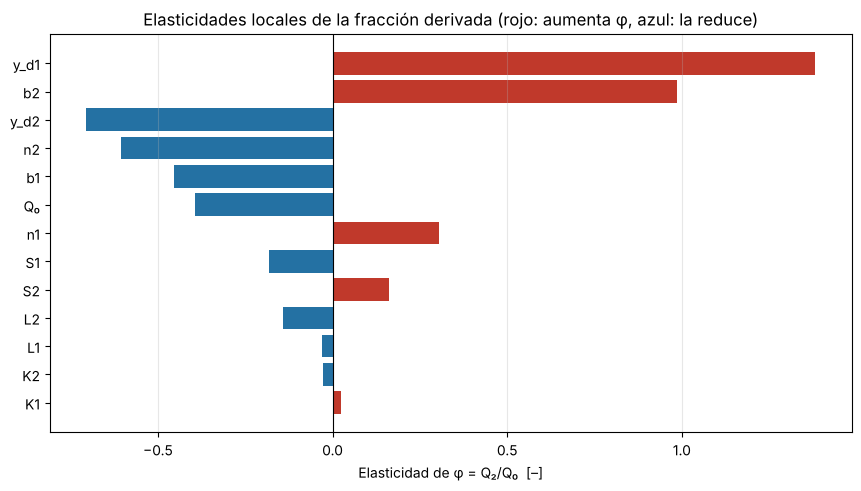

In [8]:
orden = E_imp["E(φ)"].abs().sort_values(ascending=False)
print("Parámetros ordenados por |E(φ)|:")
for nombre, val in orden.items():
    print(f"  {nombre:4s}  E = {E_imp.loc[nombre, 'E(φ)']:+.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
ordenado = E_imp["E(φ)"].reindex(orden.index)
colores = ["#c0392b" if v > 0 else "#2471a3" for v in ordenado.values]
ax.barh(range(len(ordenado)), ordenado.values, color=colores)
ax.set_yticks(range(len(ordenado))); ax.set_yticklabels(ordenado.index); ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Elasticidad de φ = Q₂/Q₀  [–]")
ax.set_title("Elasticidades locales de la fracción derivada (rojo: aumenta φ, azul: la reduce)")
ax.grid(True, axis="x", alpha=0.3)
plt.show()

## 7. Más allá de la linealización: araña y tornado

La elasticidad es local. Se vuelve a **resolver el sistema completo** con cada parámetro variando de −20 % a +20 % (todos subcríticos y con Newton convergido) para ver el comportamiento no lineal.

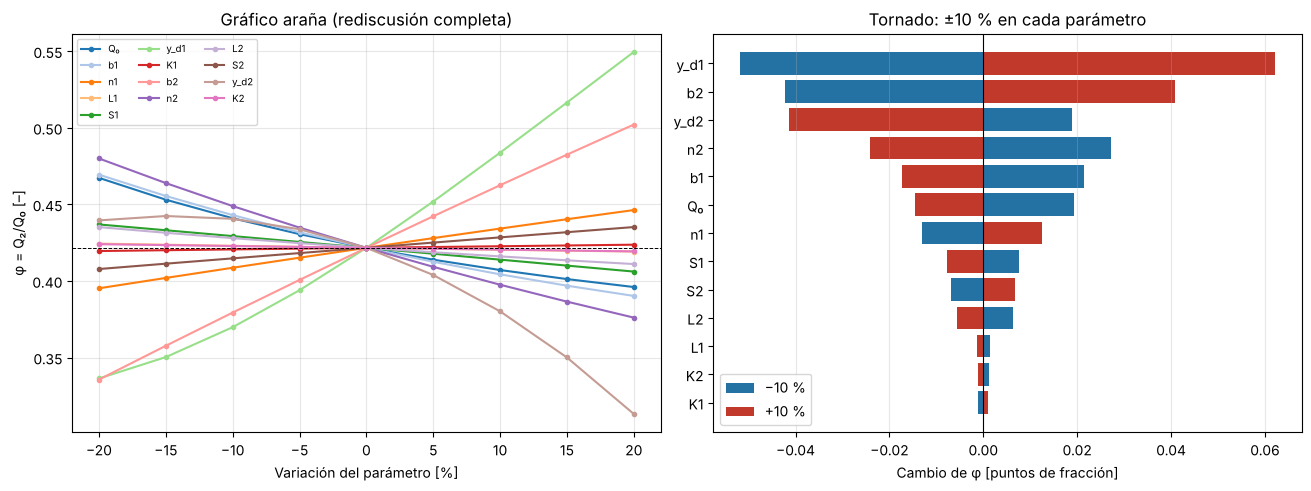

Asimetría relativa a ±20 % (0 = lineal):
y_d2    0.717
Q₀      0.282
b1      0.207
y_d1    0.200
n2      0.123
L2      0.122
L1      0.059
n1      0.034
b2      0.033
K1      0.012
K2      0.011
S2      0.010
S1      0.008


In [9]:
deltas = np.linspace(-0.20, 0.20, 9)
arana = {}
for p in PARAMS:
    v = valor(datos, p); fila = []
    for s in deltas:
        d2 = con_valor(datos, p, v*(1 + s))
        x2 = resolver(d2)
        y2 = salidas(x2, d2)
        # comprobacion fisica: subcritico en la union en ambos ramales
        for Q, b in ((x2[0], d2["ramal1"]["b"]), (x2[1], d2["ramal2"]["b"])):
            assert Q/(b*y2["yJ"])/np.sqrt(d2["g"]*y2["yJ"]) < 1, "Solución supercrítica"
        fila.append(y2["phi"])
    arana[NOMBRES[p[0]]] = fila
arana = pd.DataFrame(arana, index=np.round(100*deltas, 6))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
cmap = plt.get_cmap("tab20")
for j, c in enumerate(arana.columns):
    ax[0].plot(arana.index, arana[c], marker="o", ms=3, color=cmap(j), label=c)
ax[0].axhline(y_base["phi"], color="k", lw=0.7, ls="--")
ax[0].set_xlabel("Variación del parámetro [%]"); ax[0].set_ylabel("φ = Q₂/Q₀ [–]")
ax[0].set_title("Gráfico araña (rediscusión completa)"); ax[0].grid(alpha=0.3); ax[0].legend(ncol=3, fontsize=7)

# Tornado a ±10 %
t_m = arana.loc[-10.0] - y_base["phi"]
t_p = arana.loc[10.0] - y_base["phi"]
ordT = (t_p.abs() + t_m.abs()).sort_values(ascending=False).index
yy = np.arange(len(ordT))
ax[1].barh(yy, t_m[ordT].values, color="#2471a3", label="−10 %")
ax[1].barh(yy, t_p[ordT].values, color="#c0392b", label="+10 %")
ax[1].set_yticks(yy); ax[1].set_yticklabels(ordT); ax[1].invert_yaxis(); ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("Cambio de φ [puntos de fracción]"); ax[1].set_title("Tornado: ±10 % en cada parámetro")
ax[1].legend(); ax[1].grid(True, axis="x", alpha=0.3)
plt.show()

asim = (arana.loc[20.0] + arana.loc[-20.0] - 2*y_base["phi"])/(arana.loc[20.0] - arana.loc[-20.0]).abs()
print("Asimetría relativa a ±20 % (0 = lineal):")
print(asim.abs().sort_values(ascending=False).round(3).to_string())

## 8. Modo de diseño: sensibilidad del ancho requerido $b_2$

En el modo B se impone $\varphi$ y se calcula $b_2$. Los parámetros son ahora los mismos menos $b_2$ (que es salida), más la fracción objetivo $\varphi$.

In [10]:
PARAMS_B = [p for p in PARAMS if p[0] != "b2"] + [("phi", None, "phi")]
NOMBRES["phi"] = "φ objetivo"

x_b = resolver(datos, "diseno")
E_b = sensibilidad_implicita(datos, "diseno", PARAMS_B, x_b)
E_b = E_b[["b2", "yJ"]]
E_b.index = [NOMBRES[i] for i in E_b.index]; E_b.columns = ["E(b2)", "E(y_J)"]

# verificacion independiente (rediscusion completa) para b2
def elast_b2_completa(d, params, h=1e-4):
    base = salidas(resolver(d, "diseno"), d, "diseno")
    out = {}
    for p in params:
        v = valor(d, p)
        dp, dm = con_valor(d, p, v*(1 + h)), con_valor(d, p, v*(1 - h))
        gp = salidas(resolver(dp, "diseno"), dp, "diseno"); gm = salidas(resolver(dm, "diseno"), dm, "diseno")
        out[p[0]] = (gp["b2"] - gm["b2"])/(2*h)/base["b2"]
    return pd.Series(out)

E_b2_fd = elast_b2_completa(datos, PARAMS_B)
dEb = np.abs(E_b["E(b2)"].values - E_b2_fd.values)
V1b_ok = bool(dEb.max() <= 1e-5)
print(f"V1b  max |E(b2) implícita − rediscusión completa| = {dEb.max():.2e}  (tol 1e-5)  ->", "CUMPLE" if V1b_ok else "NO CUMPLE")
display(E_b.sort_values("E(b2)", key=np.abs, ascending=False).style.format("{:+.4f}"))
print(f"Caso base de diseño: φ = {datos['phi']:.2f}  ->  b2 = {x_b[3]:.4f} m,  y_J = {x_b[2]-datos['ramal1']['zJ']:.4f} m")

V1b  max |E(b2) implícita − rediscusión completa| = 7.37e-08  (tol 1e-5)  -> CUMPLE


,E(b2),E(y_J)
y_d1,-1.1458,+0.6783
φ objetivo,+0.9556,-0.1277
n2,+0.6083,+0.0000
y_d2,+0.5785,+0.0000
b1,+0.5167,-0.3059
Q₀,+0.3393,+0.2371
n1,-0.3358,+0.1988
S1,+0.1652,-0.0978
L2,+0.1596,+0.0000
S2,-0.1445,+0.0000


Caso base de diseño: φ = 0.35  ->  b2 = 1.6650 m,  y_J = 1.6340 m


## 9. Propagación de incertidumbre

La elasticidad mide la respuesta por unidad **relativa** de cambio, pero los parámetros no son igual de inciertos. Un parámetro muy sensible y bien conocido pesa menos que uno moderadamente sensible y mal conocido. Se combinan ambas cosas.

**Incertidumbres supuestas (ilustrativas, no medidas).** Son un escenario de trabajo con datos hipotéticos; con datos reales del sitio hay que reemplazarlas. Desviaciones estándar $\sigma_p$:

| Parámetro | $\sigma$ | Razón de elegirla |
|---|---|---|
| $Q_0$ | 5 % | Incertidumbre de caudal de diseño |
| $b$ | 2 % | Tolerancia constructiva |
| $n$ | 10 % | Rugosidad de Manning (estimación de tabla) |
| $L$ | 2 % | Medición |
| $S$ | 5 % | Pendiente de fondo |
| $y_d$ | 0.04 m | Control aguas abajo (cota de compuerta o vertedero) |
| $K$ | **0.10 absoluta** | $K$ vale 0.2 y es un coeficiente empírico: una σ relativa pequeña no tendría sentido |

**Aporte lineal.** $\mathrm{Var}(\varphi)\approx\sum_i\big(\partial\varphi/\partial p_i\;\sigma_i\big)^2$ (parámetros independientes). **Comprobación** (V5): Monte Carlo con semilla fija, parámetros normales independientes, 5000 realizaciones, que **resuelve el sistema no lineal completo**. Criterio, fijado antes de ejecutar: la desviación estándar de $\varphi$ del Monte Carlo debe coincidir con la lineal a ±15 %.

In [11]:
SEMILLA = 20261017
N_MC = 5000
sigma = {}
for p in PARAMS:
    v = valor(datos, p)
    if p[2] == "Q0": sigma[p[0]] = 0.05*v
    elif p[2] == "b": sigma[p[0]] = 0.02*v
    elif p[2] == "n": sigma[p[0]] = 0.10*v
    elif p[2] == "L": sigma[p[0]] = 0.02*v
    elif p[2] == "S": sigma[p[0]] = 0.05*v
    elif p[2] == "yd": sigma[p[0]] = 0.04
    elif p[2] == "K": sigma[p[0]] = 0.10

# derivada absoluta dphi/dp = E * phi / p
dphi = {p[0]: E_imp.loc[NOMBRES[p[0]], "E(φ)"]*y_base["phi"]/valor(datos, p) for p in PARAMS}
aporte = pd.Series({NOMBRES[k]: (dphi[k]*sigma[k])**2 for k in dphi})
var_lin = aporte.sum(); sd_lin = np.sqrt(var_lin)

rng = np.random.default_rng(SEMILLA)
muestras = {p[0]: rng.normal(valor(datos, p), sigma[p[0]], N_MC) for p in PARAMS}
phi_mc, ok_n = np.empty(N_MC), 0
for i in range(N_MC):
    d2 = copy.deepcopy(datos)
    for p in PARAMS:
        val = max(muestras[p[0]][i], 1e-6)           # evita valores no fisicos
        if p[1] is None: d2[p[2]] = val
        else: d2[p[1]][p[2]] = val
    try:
        x2 = resolver(d2); phi_mc[i] = x2[1]/d2["Q0"]; ok_n += 1
    except Exception:
        phi_mc[i] = np.nan
phi_mc = phi_mc[~np.isnan(phi_mc)]
sd_mc = phi_mc.std(ddof=1)
V5_ok = abs(sd_mc/sd_lin - 1) <= 0.15
print(f"Realizaciones resueltas: {ok_n} de {N_MC}")
print(f"φ base = {y_base['phi']:.4f}   media MC = {phi_mc.mean():.4f}   σ(lineal) = {sd_lin:.4f}   σ(MC) = {sd_mc:.4f}")
print(f"V5  σ_MC/σ_lineal − 1 = {100*(sd_mc/sd_lin - 1):+.1f} %  (tol ±15 %)  ->", "CUMPLE" if V5_ok else "NO CUMPLE")
print(f"    Error estándar de σ_MC ≈ {sd_mc/np.sqrt(2*(len(phi_mc)-1)):.5f}")
print(f"    Intervalo central 90 % de φ (MC): [{np.percentile(phi_mc, 5):.4f}, {np.percentile(phi_mc, 95):.4f}]")

Realizaciones resueltas: 5000 de 5000
φ base = 0.4216   media MC = 0.4228   σ(lineal) = 0.0367   σ(MC) = 0.0367
V5  σ_MC/σ_lineal − 1 = +0.1 %  (tol ±15 %)  -> CUMPLE
    Error estándar de σ_MC ≈ 0.00037
    Intervalo central 90 % de φ (MC): [0.3647, 0.4846]


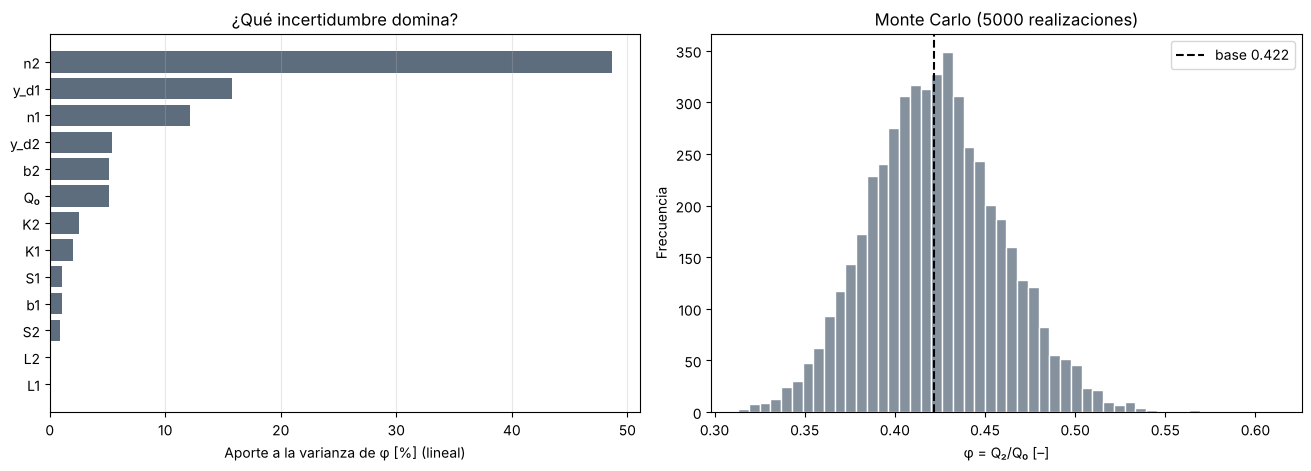

,σ supuesta,∂φ/∂p,|E(φ)|,Aporte a Var(φ) [%]
n2,0.0018,-14.2086,0.607,48.7
y_d1,0.0400,+0.3641,1.382,15.8
n1,0.0015,+8.5276,0.303,12.2
y_d2,0.0400,-0.2124,0.705,5.4
b2,0.0400,+0.2078,0.986,5.1
Q₀,0.6000,-0.0138,0.394,5.1
K2,0.1000,-0.0587,0.028,2.6
K1,0.1000,+0.0516,0.024,2.0
S1,0.0000,-96.1443,0.182,1.1
b1,0.0600,-0.0639,0.455,1.1


In [12]:
share = (100*aporte/var_lin).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
ax[0].barh(range(len(share)), share.values, color="#5d6d7e")
ax[0].set_yticks(range(len(share))); ax[0].set_yticklabels(share.index); ax[0].invert_yaxis()
ax[0].set_xlabel("Aporte a la varianza de φ [%] (lineal)"); ax[0].set_title("¿Qué incertidumbre domina?"); ax[0].grid(True, axis="x", alpha=0.3)
ax[1].hist(phi_mc, bins=50, color="#85929e", edgecolor="white")
ax[1].axvline(y_base["phi"], color="k", ls="--", label=f"base {y_base['phi']:.3f}")
ax[1].set_xlabel("φ = Q₂/Q₀ [–]"); ax[1].set_ylabel("Frecuencia"); ax[1].set_title(f"Monte Carlo ({len(phi_mc)} realizaciones)")
ax[1].legend(); plt.show()

tabla_aporte = pd.DataFrame({"σ supuesta": [sigma[p[0]] for p in PARAMS], "∂φ/∂p": [dphi[p[0]] for p in PARAMS],
                              "|E(φ)|": [abs(E_imp.loc[NOMBRES[p[0]], "E(φ)"]) for p in PARAMS]},
                            index=[NOMBRES[p[0]] for p in PARAMS])
tabla_aporte["Aporte a Var(φ) [%]"] = 100*aporte/var_lin
display(tabla_aporte.sort_values("Aporte a Var(φ) [%]", ascending=False).style.format(
    {"σ supuesta": "{:.4f}", "∂φ/∂p": "{:+.4f}", "|E(φ)|": "{:.3f}", "Aporte a Var(φ) [%]": "{:.1f}"}))

## 10. ¿Cuánto debería cambiar $K$ para mover el reparto? (pregunta ligada al modelo 2D)

En la Parte 1 se dijo que $K_i$ condensa la separación del flujo en la unión, que el modelo 2D captura y este modelo no. Una consecuencia cuantificable: **¿cuánto tendría que valer $K_2$ para producir un cambio dado de $\varphi$?** Se resuelve con el mismo Newton, variando $K_2$ con continuación.

In [13]:
def phi_de_K2(K2):
    d2 = con_valor(datos, ("K2", "ramal2", "K"), K2)
    return resolver(d2)[1]/datos["Q0"]

Ks = np.array([0.0, 0.2, 0.5, 1.0, 2.0, 3.0, 5.0])
phis = np.array([phi_de_K2(k) for k in Ks])
tK = pd.DataFrame({"K2": Ks, "φ": phis, "Δφ respecto del base": phis - y_base["phi"]})
display(tK.style.format({"K2": "{:.1f}", "φ": "{:.4f}", "Δφ respecto del base": "{:+.4f}"}).hide(axis="index"))

# K2 necesario para Δφ = −0.05 (biseccion propia)
objetivo = y_base["phi"] - 0.05
lo, hi = 0.2, 20.0
if (phi_de_K2(lo) - objetivo)*(phi_de_K2(hi) - objetivo) < 0:
    for _ in range(60):
        mid = 0.5*(lo + hi)
        if (phi_de_K2(lo) - objetivo)*(phi_de_K2(mid) - objetivo) <= 0: hi = mid
        else: lo = mid
    K2_nec = 0.5*(lo + hi)
    print(f"Para reducir φ en 0.05 (de {y_base['phi']:.3f} a {objetivo:.3f}) haría falta K2 ≈ {K2_nec:.2f} (el valor base es {datos['ramal2']['K']:.2f}).")
else:
    K2_nec = None
    print("Con K2 en [0.2, 20] no se alcanza esa reducción de φ.")

K2,φ,Δφ respecto del base
0.0,0.4340,+0.0124
0.2,0.4216,+0.0000
0.5,0.4053,-0.0163
1.0,0.3828,-0.0388
2.0,0.3490,-0.0726
3.0,0.3241,-0.0975
5.0,0.2888,-0.1328


Para reducir φ en 0.05 (de 0.422 a 0.372) haría falta K2 ≈ 1.29 (el valor base es 0.20).


## 11. Resumen de verificaciones

In [14]:
resumen = pd.DataFrame([
    ["V1", "Elasticidades implícitas vs rediscusión completa (modo A)", f"{dE.values.max():.1e}", "≤ 1e-5", V1_ok],
    ["V1b", "Ídem para b2 (modo B)", f"{dEb.max():.1e}", "≤ 1e-5", V1b_ok],
    ["V2", "Conservación de masa en las sensibilidades", f"{max(res_V2):.1e}", "≤ 1e-9", V2_ok],
    ["V3", "Simetría con ramales idénticos", f"{max(dsim):.1e}", "≤ 1e-7", V3_ok],
    ["V4", "Predicción lineal a ±1 % (error relativo)", f"{100*err1.max():.2f} % ({err1.idxmax()})", "≤ 2 %", V4_ok],
    ["V4b", "Ídem a ±0.1 % (diagnóstico de curvatura)", f"{100*err01.max():.3f} %", "≤ 2 %", V4b_ok],
    ["V5", "σ de φ: Monte Carlo vs lineal", f"{100*(sd_mc/sd_lin - 1):+.1f} %", "±15 %", V5_ok]],
    columns=["Prueba", "Qué se verifica", "Obtenido", "Tolerancia", "¿Cumple?"])
display(resumen.style.hide(axis="index"))
print(f"\n{int(resumen['¿Cumple?'].sum())} de {len(resumen)} pruebas cumplen.")

Prueba,Qué se verifica,Obtenido,Tolerancia,¿Cumple?
V1,Elasticidades implícitas vs rediscusión completa (modo A),2.8e-08,≤ 1e-5,True
V1b,Ídem para b2 (modo B),7.4e-08,≤ 1e-5,True
V2,Conservación de masa en las sensibilidades,9.9e-11,≤ 1e-9,True
V3,Simetría con ramales idénticos,1.5e-08,≤ 1e-7,True
V4,Predicción lineal a ±1 % (error relativo),3.92 % (y_d2),≤ 2 %,False
V4b,Ídem a ±0.1 % (diagnóstico de curvatura),0.380 %,≤ 2 %,True
V5,σ de φ: Monte Carlo vs lineal,+0.1 %,±15 %,True



6 de 7 pruebas cumplen.


## 12. Conclusiones, límites y qué sigue

(Las cifras de esta sección salen de las tablas anteriores; se ejecutan en la celda siguiente para que no queden desactualizadas.)

In [15]:
top3 = E_imp["E(φ)"].abs().sort_values(ascending=False).head(3)
txt = "- **Mayor elasticidad de φ:** " + ", ".join(f"{k} ({E_imp.loc[k, 'E(φ)']:+.2f})" for k in top3.index) + ".\n"
top_var = share.head(3)
txt += "- **Mayor aporte a la varianza de φ con las incertidumbres supuestas:** " + ", ".join(f"{k} ({v:.0f} %)" for k, v in top_var.items()) + ".\n"
txt += f"- **Pérdida local K:** |E(φ)| = {abs(E_imp.loc['K1','E(φ)']):.3f} (K1) y {abs(E_imp.loc['K2','E(φ)']):.3f} (K2), es decir, muy baja. "
if K2_nec is not None:
    txt += f"Para bajar φ en 0.05 haría falta K2 ≈ {K2_nec:.1f}, contra 0.2 del caso base.\n"
else:
    txt += "Con K2 hasta 20 no se logra bajar φ en 0.05.\n"
txt += f"- **Incertidumbre de φ** con las σ supuestas: ±{sd_mc:.3f} (1σ, Monte Carlo) sobre un valor base de {y_base['phi']:.3f}.\n"
display(Markdown(txt))

- **Mayor elasticidad de φ:** y_d1 (+1.38), b2 (+0.99), y_d2 (-0.71).
- **Mayor aporte a la varianza de φ con las incertidumbres supuestas:** n2 (49 %), y_d1 (16 %), n1 (12 %).
- **Pérdida local K:** |E(φ)| = 0.024 (K1) y 0.028 (K2), es decir, muy baja. Para bajar φ en 0.05 haría falta K2 ≈ 1.3, contra 0.2 del caso base.
- **Incertidumbre de φ** con las σ supuestas: ±0.037 (1σ, Monte Carlo) sobre un valor base de 0.422.


**Límites de este análisis.**

1. **Local y con datos hipotéticos.** Las elasticidades valen alrededor del caso base de la Parte 1; con datos reales de un sitio cambiarán. La sección 7 muestra que a ±20 % la respuesta se aparta de la lineal en algunos parámetros.
2. **Incertidumbres supuestas.** El ranking por aporte a la varianza depende de las $\sigma$ de la sección 9, que son ilustrativas. El ranking por elasticidad no depende de ellas.
3. **Parámetros independientes.** Se supone independencia entre parámetros. En la práctica $n_1$ y $n_2$, o $K_1$ y $K_2$, podrían estar correlacionados.
4. **Sensibilidad al modelo, no al fenómeno.** Esto analiza el modelo 1D con nivel común. Que $K$ tenga baja elasticidad aquí **no** implica que la separación del flujo sea poco importante en un canal real; solo que, **en esta formulación**, $K$ es una palanca débil para reproducir un reparto distinto. La discrepancia con el modelo 2D en el reparto puede no ser representable con $K$ solo; eso se evaluará en la fase del modelo 2D con HEC-RAS.
5. **No se exploró** una sensibilidad global tipo Sobol (interacciones entre parámetros). El Monte Carlo solo valida la varianza total, no separa interacciones.

**Siguiente fase.** Modelo 2D en HEC-RAS (3 mallas, balance de masa) y métrica de comparación sobre $\varphi$, con las discrepancias esperadas acotadas.

## 13. Referencias

* Chaudhry, M. H. (2008). *Open-Channel Flow* (2.ª ed.). Springer. Cap. 6 (uniones de canales, Ecs. 6-58 a 6-63).
* Saltelli, A., Ratto, M., Andres, T., Campolongo, F., Cariboni, J., Gatelli, D., Saisana, M., y Tarantola, S. (2008). *Global Sensitivity Analysis: The Primer*. Wiley. (Marco general de elasticidades y de sensibilidad local frente a global; verificar edición antes de citar.)